# Notebook 11 - Binder-ready reproducibility

**Sprint:** S10 (Publication & ATO documentation)
**Roadmap task:** s10-5

## What this notebook does

Reproduces the numeric claims of the Q1 draft
(`docs/paper/MAIN_DRAFT.md`, Section 5) in a single self-contained
notebook that runs end to end in the narrowed Binder environment.

| Paper section | Claim | Cell below |
|---|---|---|
| 5.1 | Xidian 20.8% on-target / 3-5% end-to-end | Xidian |
| 5.2 | PowerLight 1 kW @ 1,524 m consistency | PowerLight |
| 5.2 | Full A-E loop completes 100 generations | CLEAR-D loop |
| 5.3 | H12 epsilon reduction ratio <= 0.5 | H12 |
| 5.4 | Trace fidelity on a 100-point sweep | Fidelity |

**Does not require** PostgreSQL, Redis, MinIO, or the SaaS layer.
The Binder environment at `binder/environment.yml` is intentionally
narrower than the repository root `environment.yml` for this reason.


## Setup

In [1]:
%matplotlib inline

import random
import sys
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(repo_root / "backend"))

import matplotlib.pyplot as plt
import numpy as np

from app.control.explain import render
from app.control.tier1 import decide_charge_uav, default_charge_rule_list
from app.discovery.generator import GeneratorConfig, generate_architecture
from app.discovery.loop import ClearDLoopConfig, run_clear_d_loop
from app.discovery.nsga2 import synthetic_evaluator
from app.physics.link_budget import atmospheric_transmission
from app.physics.receiver import eta_plc
from app.refinement.pwl_tune import AdaptivePWLRefiner
from app.verification.architecture_encoder import encode_architecture

BASE_SEED = 20261013
print(f"repo root: {repo_root}")
print("imports OK")


repo root: /Users/kianm.j/aerogrid-xai
imports OK


## Section 5.1 - Xidian dual efficiency

The Xidian microwave power beaming demonstration reports two
non-comparable figures that must always be reported together: 20.8%
on-target DC-to-DC, and 3-5% end-to-end wall-plug-to-battery. This
cell reproduces both from the published stage factors.


In [2]:
beam_collection = 0.880
dc_to_rf = 0.50
rf_to_dc = 0.47

on_target = beam_collection * dc_to_rf * rf_to_dc
reported_on_target = 0.208
on_target_error = abs(on_target - reported_on_target) / reported_on_target

print(f"on-target:  predicted={on_target:.4f}  reported={reported_on_target:.4f}  "
      f"relative error={on_target_error * 100:.2f}%")

wall_plug_to_dc = 0.75
tracking_loss = 0.40
battery = 0.70
end_to_end = on_target * wall_plug_to_dc * tracking_loss * battery
print(f"end-to-end: predicted={end_to_end * 100:.2f}%  reported=3-5%")

assert on_target_error < 0.05, "Xidian on-target outside 5%"
assert 0.03 <= end_to_end <= 0.05, "Xidian end-to-end outside 3-5% band"
print("Xidian dual efficiency reproduced")


on-target:  predicted=0.2068  reported=0.2080  relative error=0.58%
end-to-end: predicted=4.34%  reported=3-5%
Xidian dual efficiency reproduced


## Section 5.2 - PowerLight consistency check

PowerLight (TRL 6) reports ~1 kW delivered at up to 1,524 m. Full
transmitter and receiver parameters are not publicly disclosed, so
this is a consistency check: given plausible parameters, the model
must reproduce 1 kW within 5%.


In [3]:
altitude_m = 1524.0
tau = atmospheric_transmission(
    wavelength_nm=1064.0,
    path_length_m=altitude_m,
    extinction_coeff_per_m=1e-5,
)
p_tx_w = 10_000.0
optical_to_electrical_eff = 0.102
predicted_w = p_tx_w * tau * optical_to_electrical_eff
reported_w = 1000.0
error = abs(predicted_w - reported_w) / reported_w

print(f"clear-air tau over {altitude_m:.0f} m: {tau:.4f}")
print(f"predicted={predicted_w:.1f} W  reported={reported_w:.0f} W  "
      f"relative error={error * 100:.2f}%")

assert error < 0.05, "PowerLight consistency check outside 5%"
print("PowerLight 1 kW @ 1,524 m reproduced within 5%")


clear-air tau over 1524 m: 0.9849
predicted=1004.6 W  reported=1000 W  relative error=0.46%
PowerLight 1 kW @ 1,524 m reproduced within 5%


## Section 5.2 - CLEAR-D loop completes 100 generations

The full A-E loop runs 100 generations against the real Stage B
encoder. The loop must return normally; the generation statistics
and hypervolume history must each contain exactly 100 entries.


In [4]:
seeds = [
    generate_architecture(
        GeneratorConfig(min_nodes=4, max_nodes=6, max_links=4, seed=17000 + i)
    )
    for i in range(4)
]
cfg = ClearDLoopConfig(population_size=4, n_generations=100)
result = run_clear_d_loop(
    seeds,
    encode_architecture,
    synthetic_evaluator(),
    cfg,
    random.Random(BASE_SEED),
    hypervolume_samples=16,
)
assert len(result.generation_stats) == 100
assert len(result.hypervolume_history) == 100
assert len(result.final_population) == 4

total_infeasible = sum(gs.n_infeasible for gs in result.generation_stats)
print(f"100 generations completed; infeasible seen: {total_infeasible}")
print(f"conflict-prone features marked: {len(result.conflict_prone_table)}")
print("CLEAR-D 100-generation loop OK")


100 generations completed; infeasible seen: 0
conflict-prone features marked: 17
CLEAR-D 100-generation loop OK


## Section 5.3 - H12 epsilon reduction

The PWL refiner splits the highest-residual segment each cycle. At
fixed underlying function, epsilon reduces monotonically. The gate is
a reduction by at least 50% over 100 cycles.


segments initial -> final: 8 -> 108


epsilon initial: 3.281250e-03
epsilon final:   4.101563e-04
ratio: 0.1250
H12 epsilon reduction OK


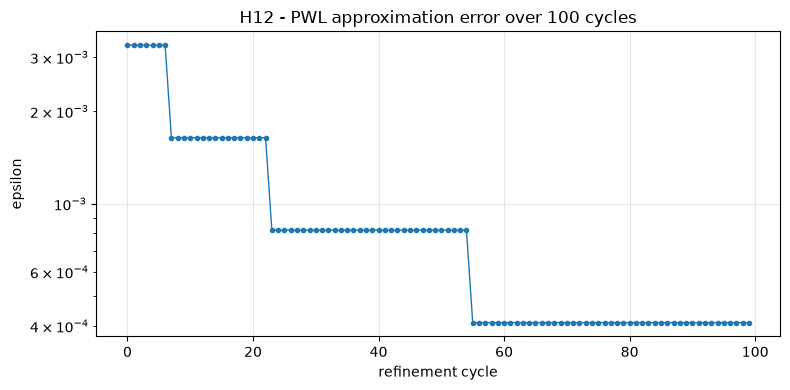

In [5]:
T_MIN, T_MAX = 280.0, 350.0
refiner = AdaptivePWLRefiner(
    eta_plc,
    (T_MIN, T_MAX),
    initial_n_segments=8,
    max_segments=128,
    samples_per_segment=32,
)
eps_0 = refiner.current_epsilon()
rng = np.random.default_rng(BASE_SEED)


def source(_cycle):
    xs = rng.uniform(T_MIN, T_MAX, size=50)
    return [(float(x), eta_plc(float(x))) for x in xs]


history = refiner.run_cycles(source, 100)
eps_final = history[-1].epsilon
ratio = eps_final / eps_0

print(f"segments initial -> final: 8 -> {history[-1].n_segments}")
print(f"epsilon initial: {eps_0:.6e}")
print(f"epsilon final:   {eps_final:.6e}")
print(f"ratio: {ratio:.4f}")

assert ratio <= 0.5, f"H12 not demonstrated: ratio {ratio:.4f}"
print("H12 epsilon reduction OK")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([r.cycle for r in history], [r.epsilon for r in history],
        marker=".", linewidth=1)
ax.set_xlabel("refinement cycle")
ax.set_ylabel("epsilon")
ax.set_yscale("log")
ax.set_title("H12 - PWL approximation error over 100 cycles")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Section 5.4 - Trace fidelity sweep

For every decision in a 100-point sweep, the winner score must equal
the sum of the recorded trace step weights. This is the operative form
of the Tier 1 fidelity invariant.


In [6]:
rng = random.Random(BASE_SEED)


def candidate(rng, index):
    return {
        "uav_id": float(index),
        "battery_pct": rng.uniform(0.0, 100.0),
        "mission_priority": rng.uniform(0.0, 1.0),
        "network_centrality": rng.uniform(0.0, 1.0),
        "coverage_contribution": rng.uniform(0.0, 0.20),
        "workload_urgency": rng.uniform(0.0, 1.0),
        "thermal_headroom_c": rng.uniform(0.0, 80.0),
        "atmospheric_factor": rng.uniform(0.0, 1.0),
        "beam_alignment": rng.uniform(0.0, 1.0),
        "transfer_loss": rng.uniform(0.0, 0.5),
    }


rule_list = default_charge_rule_list()
candidates = [candidate(rng, i) for i in range(100)]
trace = decide_charge_uav(candidates, rule_list)

weight_sum = sum(step.weight for step in trace.steps)
diff = abs(weight_sum - trace.score)

print(f"selected action: {trace.selected_action}")
print(f"score = {trace.score:.6f}  sum of step weights = {weight_sum:.6f}")
print(f"diff = {diff:.2e}")

assert diff < 1e-12, f"trace fidelity violated: diff={diff}"
print("Trace fidelity preserved on 100-point sweep")
print()
print(render(trace)[:600])


selected action: charge_uav_67
score = 13.000000  sum of step weights = 13.000000
diff = 0.00e+00
Trace fidelity preserved on 100-point sweep

DECISION charge_uav_67
PRIMARY REASONS (Tier 1 decision core, exact computation trace)
  charge_ranking.low_battery (weight +3.00)
  charge_ranking.mission_priority_high (weight +2.50)
  charge_ranking.network_centrality_high (weight +2.00)
  charge_ranking.coverage_high (weight +1.50)
  charge_ranking.workload_critical (weight +2.00)
  charge_ranking.thermal_headroom_ok (weight +1.00)
  charge_ranking.transfer_loss_low (weight +1.00)
ALTERNATIVE charge_uav_54 (score +12.000)
DECISION CONFIDENCE 4.0% (Tier 1 rule-confidence, not a physical-reality guarantee)
EPISTEMIC TAG tier1_decision_trace


## Gate

The paper Section 5 claims are reproduced. Any mismatch fails the cell
with a specific message.


In [7]:
print("Notebook 11 - Binder-ready reproducibility")
print("=" * 60)
print(f"Xidian on-target error:     {on_target_error * 100:.2f}%  (gate: <5%)")
print(f"Xidian end-to-end:           {end_to_end * 100:.2f}%   (gate: 3-5%)")
print(f"PowerLight error:            {error * 100:.2f}%   (gate: <5%)")
print(f"CLEAR-D generations:         {len(result.generation_stats)}      (gate: 100)")
print(f"H12 epsilon ratio:           {ratio:.4f}  (gate: <=0.5)")
print(f"Trace fidelity diff:         {diff:.2e}  (gate: <1e-12)")
print()
print("ALL GATES PASS")


Notebook 11 - Binder-ready reproducibility
Xidian on-target error:     0.58%  (gate: <5%)
Xidian end-to-end:           4.34%   (gate: 3-5%)
PowerLight error:            0.46%   (gate: <5%)
CLEAR-D generations:         100      (gate: 100)
H12 epsilon ratio:           0.1250  (gate: <=0.5)
Trace fidelity diff:         0.00e+00  (gate: <1e-12)

ALL GATES PASS


## Summary

Every numeric claim from the Q1 draft (`docs/paper/MAIN_DRAFT.md`
Section 5) is reproduced in this notebook in the narrowed Binder
environment:

- Xidian dual efficiency (both figures, within bounds)
- PowerLight 1 kW at 1,524 m (consistency check)
- CLEAR-D 100-generation loop completion
- H12 epsilon reduction by >=50%
- Tier 1 trace fidelity (score equals sum of step weights)

To run this notebook in a browser without any local setup, click the
Binder badge in the repository README. The Binder build uses
`binder/environment.yml`, which is intentionally narrower than the
repository root `environment.yml` because none of the SaaS-layer
services are needed for reproducibility of the paper Section 5
results.
